In [2]:
import sys

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import myutils

workspace,experiment=myutils.workspace()
data_dir = experiment/"scGPT/data/ms"
data_dir

PosixPath('/omics/odcf/analysis/OE0290_projects/heroes-aya_pools/AG_Thongjuea/Code/10x_multiomics/Selina/project/experiment03-scGPT/scGPT/data/ms')

In [3]:
# READ ----------------------------------------------------------------------- #
adata = sc.read(data_dir / "c_data.h5ad")
adata_test = sc.read(data_dir / "filtered_ms_adata.h5ad")

# edit categorie types and index
adata.obs["celltype"] = adata.obs["Factor Value[inferred cell type - authors labels]"].astype("category")
adata_test.obs["celltype"] = adata_test.obs["Factor Value[inferred cell type - authors labels]"].astype("category")
adata.obs["batch_id"]  = adata.obs["str_batch"] = "0"
adata_test.obs["batch_id"]  = adata_test.obs["str_batch"] = "1"          
adata.var.set_index(adata.var["gene_name"], inplace=True)
adata_test.var.set_index(adata.var["gene_name"], inplace=True)
adata_test_raw = adata_test.copy()
adata_batch0_raw = adata.copy()
# adata = adata.concatenate(adata_test, batch_key="str_batch")
adata = ad.concat([adata, adata_test], label="str_batch")

# batch ids to int
batch_id_labels = adata.obs["str_batch"].astype("category").cat.codes.values
adata.obs["batch_id"] = batch_id_labels
# cell types to int 
celltype_id_labels = adata.obs["celltype"].astype("category").cat.codes.values
celltypes = adata.obs["celltype"].unique()
num_types = len(np.unique(celltype_id_labels))
id2type = dict(enumerate(adata.obs["celltype"].astype("category").cat.categories))
adata.obs["celltype_id"] = celltype_id_labels
adata.write(workspace/'data/ms/ms_batches.h5ad')
# gene names as column
adata.var["gene_name"] = adata.var.index.tolist()

In [4]:
id2type

{0: 'PVALB-expressing interneuron',
 1: 'SST-expressing interneuron',
 2: 'SV2C-expressing interneuron',
 3: 'VIP-expressing interneuron',
 4: 'astrocyte',
 5: 'cortical layer 2-3 excitatory neuron A',
 6: 'cortical layer 2-3 excitatory neuron B',
 7: 'cortical layer 4 excitatory neuron',
 8: 'cortical layer 5-6 excitatory neuron',
 9: 'endothelial cell',
 10: 'microglial cell',
 11: 'mixed excitatory neuron',
 12: 'mixed glial cell?',
 13: 'oligodendrocyte A',
 14: 'oligodendrocyte C',
 15: 'oligodendrocyte precursor cell',
 16: 'phagocyte',
 17: 'pyramidal neuron?'}

In [5]:
# COMBINED ------------------------------------------------------------------- #
print(adata)
print("\nCell index has changed:")
print("BEFORE:",adata_batch0_raw.obs.index[0])
print("AFTER:",adata.obs.index[0])
print("BEFORE:",adata_test.obs.index[0])
print("AFTER:",adata.obs.index[7844])

AnnData object with n_obs × n_vars = 21312 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample 

In [6]:
# USED FOR TRAIN / VALIDATION ------------------------------------------------ #
print(adata_batch0_raw)
adata[adata.obs["str_batch"] == "0"]

AnnData object with n_obs × n_vars = 7844 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample C

View of AnnData object with n_obs × n_vars = 7844 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', '

In [6]:
# USED FOR FINAL TEST -------------------------------------------------------- #
print(adata_test_raw)
adata[adata.obs["str_batch"] == "1"]

AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample 

View of AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 

In [7]:
adata_test_raw.uns['umap']

{'params': {'a': 0.5830300205483709, 'b': 1.334166992455648}}

# UMPAS

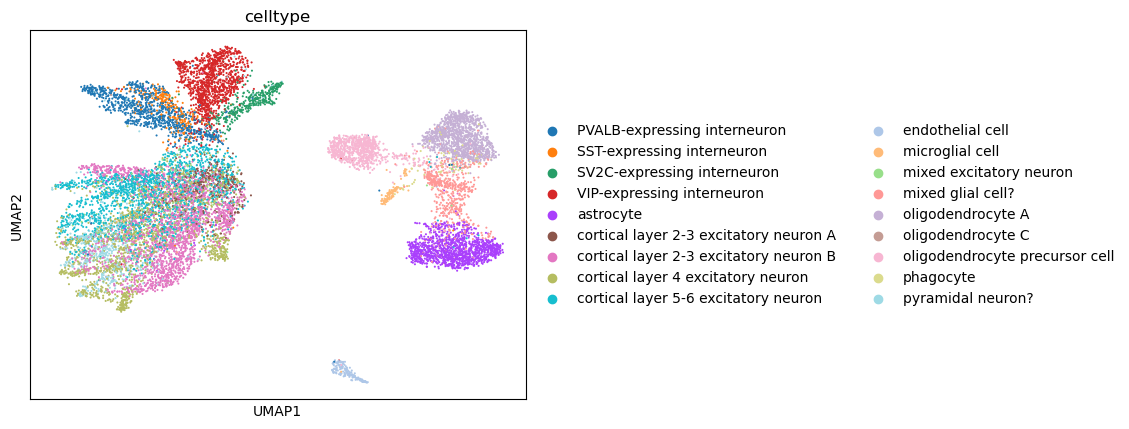

In [8]:
sc.pl.umap(adata_test, color='celltype')

In [9]:
print('adata combined')
print(f"str_batch: {', '.join(adata.obs.str_batch.unique())}")
print(f"celltype: {', '.join(adata.obs.celltype.cat.categories.to_list())}")
print('')
print('adata_test')
print(f"str_batch: {''.join(adata_test.obs.str_batch.unique())}")
print(f"celltype: {', '.join(adata_test.obs.celltype.cat.categories.to_list())}")

adata combined
str_batch: 0, 1
celltype: PVALB-expressing interneuron, SST-expressing interneuron, SV2C-expressing interneuron, VIP-expressing interneuron, astrocyte, cortical layer 2-3 excitatory neuron A, cortical layer 2-3 excitatory neuron B, cortical layer 4 excitatory neuron, cortical layer 5-6 excitatory neuron, endothelial cell, microglial cell, mixed excitatory neuron, mixed glial cell?, oligodendrocyte A, oligodendrocyte C, oligodendrocyte precursor cell, phagocyte, pyramidal neuron?

adata_test
str_batch: 1
celltype: PVALB-expressing interneuron, SST-expressing interneuron, SV2C-expressing interneuron, VIP-expressing interneuron, astrocyte, cortical layer 2-3 excitatory neuron A, cortical layer 2-3 excitatory neuron B, cortical layer 4 excitatory neuron, cortical layer 5-6 excitatory neuron, endothelial cell, microglial cell, mixed excitatory neuron, mixed glial cell?, oligodendrocyte A, oligodendrocyte C, oligodendrocyte precursor cell, phagocyte, pyramidal neuron?


In [7]:
adata_combined = adata.copy()
adata_test = adata[adata.obs["str_batch"] == "1"]
adata = adata[adata.obs["str_batch"] == "0"]
adata_test.shape, adata.shape

((13468, 3000), (7844, 3000))

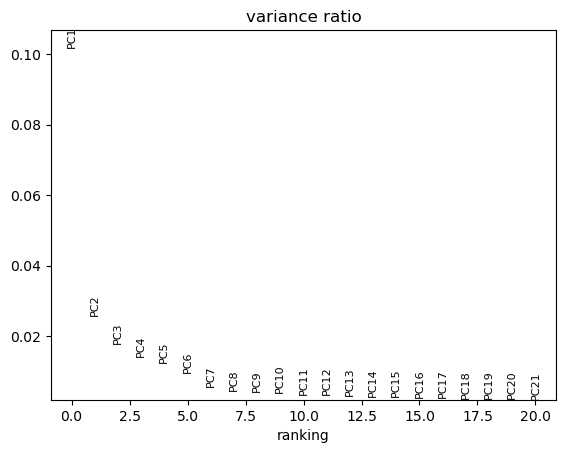

In [11]:
sc.tl.pca(adata_combined, n_comps=50, zero_center=True, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_combined, n_pcs=20)

In [12]:
sc.pp.neighbors(adata_combined, n_neighbors=20, n_pcs=30, use_rep='X_pca')
sc.tl.leiden(adata_combined, flavor='igraph',resolution=0.85,random_state=0,n_iterations=2,directed=False)
print(len(adata_combined.obs.leiden.cat.categories))

18


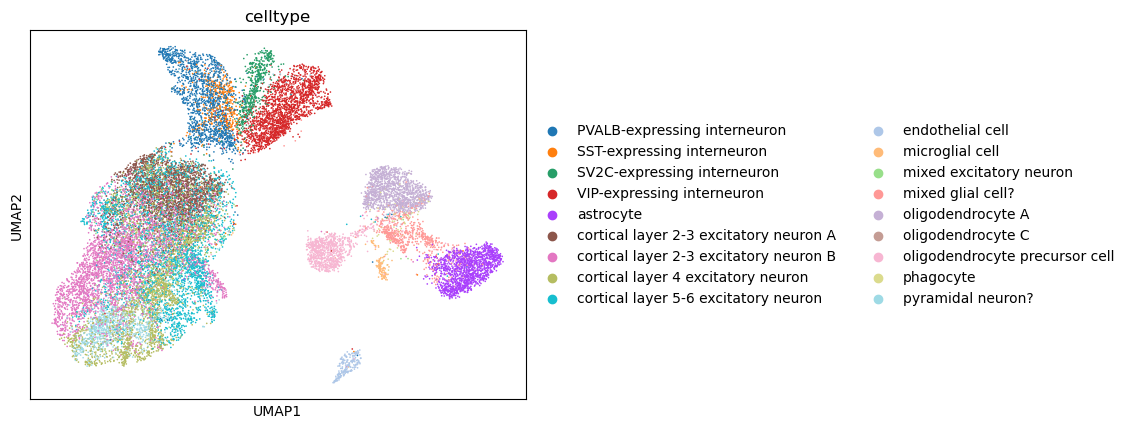

In [13]:
sc.tl.umap(adata_combined)
sc.pl.umap(adata_combined, color=["celltype"])


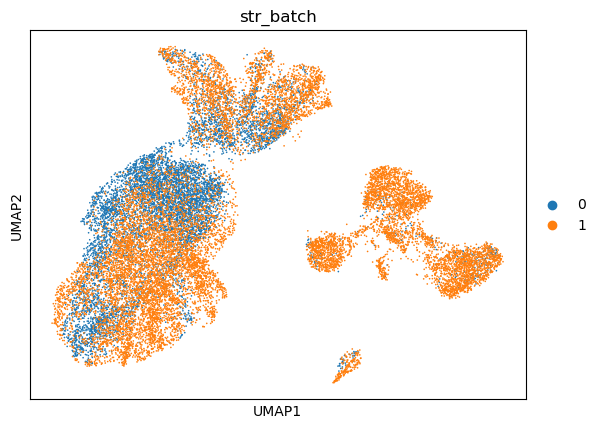

In [14]:
sc.pl.umap(adata_combined, color=["str_batch"])

In [15]:
sum(adata_combined.obs.str_batch == '0') / adata_combined.n_obs, sum(adata_combined.obs.str_batch == '1') / adata_combined.n_obs
print(sum(adata_combined.obs.str_batch == '0'),sum(adata_combined.obs.str_batch == '1'))

7844 13468


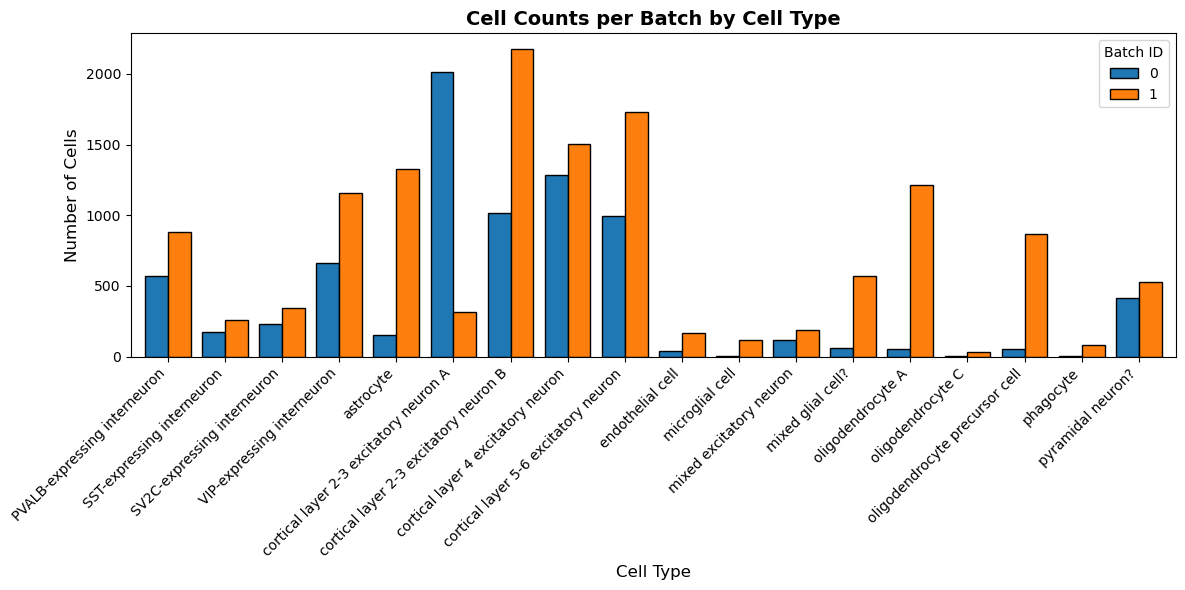

In [16]:
cell_counts = pd.crosstab(adata_combined.obs['celltype'], adata_combined.obs['batch_id'])
cell_counts.plot(kind='bar', stacked=False, figsize=(12, 6), edgecolor='black', width=0.8)

# 3. Add layout styling
plt.title("Cell Counts per Batch by Cell Type", fontsize=14, fontweight='bold')
plt.xlabel("Cell Type", fontsize=12)
plt.ylabel("Number of Cells", fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the labels so they don't overlap
plt.legend(title="Batch ID")
plt.tight_layout()

plt.show()

In [17]:
cell_counts.sort_values(0)

batch_id,0,1
celltype,,
oligodendrocyte C,3,34
phagocyte,3,82
microglial cell,4,118
endothelial cell,38,170
oligodendrocyte A,53,1216
oligodendrocyte precursor cell,55,866
mixed glial cell?,60,573
mixed excitatory neuron,114,185
astrocyte,154,1330


# Cell types

In [18]:
sc.pl.umap(adata_test_raw, color=["celltype"], show=False)
plt.close()

In [19]:
# myutils.select_celltype(adata_test_raw, 'phagocyte')


# Processing

In [8]:
import json
import shutil
from collections import Counter

from scgpt.preprocess import Preprocessor
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from scipy.sparse import issparse
from sklearn.model_selection import train_test_split


In [9]:
data_is_raw = False
filter_gene_by_counts = False
filter_cell_by_counts = False
hvg_flavor="seurat_v3" if data_is_raw else "cell_ranger"
n_bins=51
input_style = "binned" 
input_layer_key = "X_binned"

model_dir = experiment / "scGPT/save/scGPT_human"
model_config_file = model_dir / "args.json"
vocab_file = model_dir / "vocab.json"

In [10]:
vocab = GeneVocab.from_file(vocab_file)
for s in ["<pad>", "<cls>", "<eoc>"]:
    if s not in vocab:
        vocab.append_token(s)
vocab.set_default_index(vocab["<pad>"])

In [11]:
adata.var["id_in_vocab"] = [
        1 if gene in vocab else -1 for gene in adata.var["gene_name"]
    ]
print((adata.var["id_in_vocab"] < 0).sum())
adata = adata[:, adata.var["id_in_vocab"] >= 0]

192


In [12]:
preprocessor = Preprocessor(
    use_key="X",  # the key in adata.layers to use as raw data
    filter_gene_by_counts=filter_gene_by_counts,  # step 1
    filter_cell_by_counts=filter_cell_by_counts,  # step 2
    normalize_total=1e4,  # 3. whether to normalize the raw data and to what sum
    result_normed_key="X_normed",  # the key in adata.layers to store the normalized data
    log1p=data_is_raw,  # 4. whether to log1p the normalized data
    result_log1p_key="X_log1p",
    subset_hvg=False,  # 5. whether to subset the raw data to highly variable genes
    hvg_flavor=hvg_flavor,
    binning=n_bins,  # 6. whether to bin the raw data and to what number of bins
    result_binned_key="X_binned",  # the key in adata.layers to store the binned data
)
preprocessor(adata_test, batch_key=None)
preprocessor(adata, batch_key=None)

scGPT - INFO - Normalizing total counts ...
scGPT - INFO - Binning data ...
binning <Compressed Sparse Row sparse matrix of dtype 'float32'
	with 4569447 stored elements and shape (13468, 3000)>
  Coords	Values
  (0, 30)	2.573533773422241
  (0, 66)	2.573533773422241
  (0, 151)	3.227802038192749
  (0, 169)	2.573533773422241
  (0, 187)	1.9538838863372803
  (0, 192)	2.573533773422241
  (0, 215)	2.573533773422241
  (0, 220)	2.573533773422241
  (0, 227)	2.573533773422241
  (0, 238)	2.573533773422241
  (0, 257)	2.573533773422241
  (0, 275)	3.227802038192749
  (0, 288)	2.573533773422241
  (0, 292)	2.573533773422241
  (0, 306)	3.227802038192749
  (0, 307)	2.573533773422241
  (0, 315)	2.573533773422241
  (0, 316)	3.227802038192749
  (0, 322)	2.573533773422241
  (0, 325)	2.573533773422241
  (0, 347)	2.573533773422241
  (0, 359)	2.573533773422241
  (0, 464)	2.573533773422241
  (0, 496)	2.573533773422241
  (0, 497)	1.9538838863372803
  :	:
  (13467, 2659)	1.4731552600860596
  (13467, 2678)	0.75188

In [25]:

all_counts = (
    adata.layers[input_layer_key].toarray()
    if issparse(adata.layers[input_layer_key])
    else adata.layers[input_layer_key]
)
celltypes_labels = adata.obs["celltype_id"].tolist()  # make sure count from 0
celltypes_labels = np.array(celltypes_labels)
batch_ids = adata.obs["batch_id"].tolist()
num_batch_types = len(set(batch_ids))
batch_ids = np.array(batch_ids)
(
    train_data,
    valid_data,
    train_celltype_labels,
    valid_celltype_labels,
    train_batch_labels,
    valid_batch_labels,
) = train_test_split(
    all_counts, celltypes_labels, batch_ids, test_size=0.1, shuffle=True
)


train_celltypes = pd.DataFrame(dict(Counter(train_celltype_labels)),  index=['cell_count']).T
train_celltypes = pd.concat([train_celltypes, pd.DataFrame(id2type,  index=['celltype']).T], axis=1).reset_index(names='celltype_id')
train_celltypes = train_celltypes.sort_values('celltype_id').reset_index(drop=True).set_index('celltype',drop=False)

valid_celltypes = pd.DataFrame(dict(Counter(valid_celltype_labels)),  index=['cell_count']).T
valid_celltypes = pd.concat([valid_celltypes, pd.DataFrame(id2type,  index=['celltype']).T], axis=1).reset_index(names='celltype_id')
valid_celltypes = valid_celltypes.sort_values('celltype_id').reset_index(drop=True).set_index('celltype',drop=False)

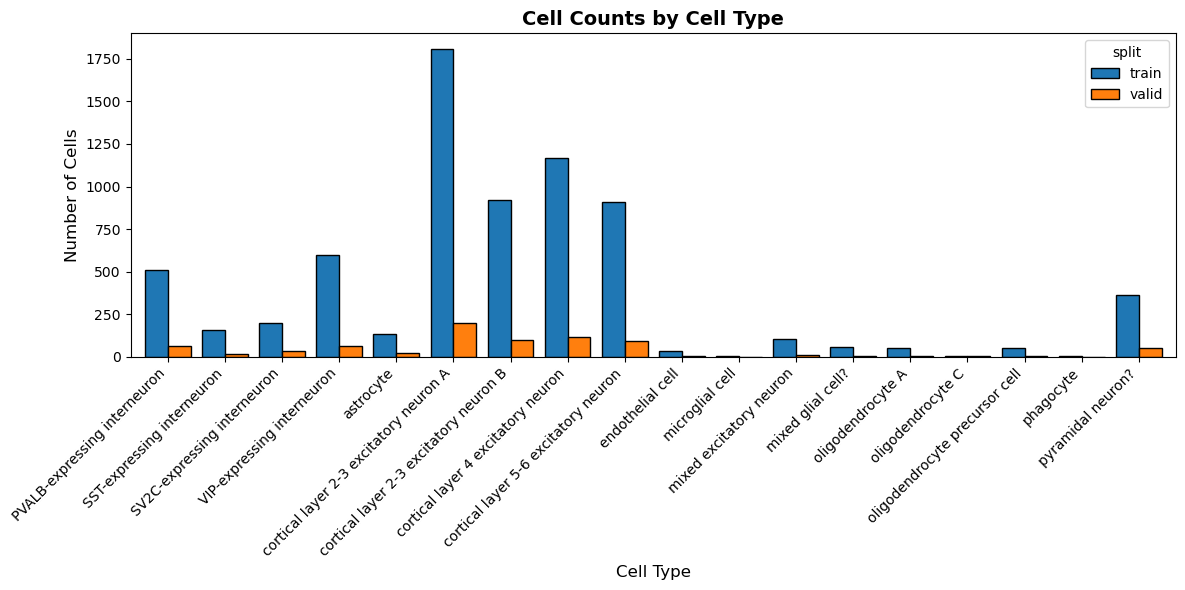

In [26]:
df = pd.DataFrame({'train':dict(train_celltypes['cell_count']),'valid':dict(valid_celltypes['cell_count'])})
df.plot(kind='bar', stacked=False, figsize=(12, 6), edgecolor='black', width=0.8)

# 3. Add layout styling
plt.title("Cell Counts by Cell Type", fontsize=14, fontweight='bold')
plt.xlabel("Cell Type", fontsize=12)
plt.ylabel("Number of Cells", fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the labels so they don't overlap
plt.legend(title="split")
plt.tight_layout()

plt.show()

In [27]:
from IPython.display import HTML

HTML(df.sort_values('train').reset_index().to_html())

,index,train,valid
0,oligodendrocyte C,2,1.0
1,phagocyte,3,NaN
2,microglial cell,4,NaN
3,endothelial cell,32,6.0
4,oligodendrocyte A,50,3.0
5,oligodendrocyte precursor cell,52,3.0
6,mixed glial cell?,56,4.0
7,mixed excitatory neuron,102,12.0
8,astrocyte,133,21.0
9,SST-expressing interneuron,154,18.0
